In [1]:

# NOTEBOOK 11 — CELL 1: ENVIRONMENT + PROJECT AUDIT
# Self-contained; safe to run more than once.

import os
import sys
import json
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch

PROJECT_NAME = "Ocular_Project"
KAGGLE_INPUT = Path("/kaggle/input")
KAGGLE_WORKING = Path("/kaggle/working")
LOCAL_PROJECT = KAGGLE_WORKING / PROJECT_NAME
LOCAL_PROJECT.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("NOTEBOOK 11 — GAN vs DIFFUSION")
print("=" * 65)

print("\n[1] Runtime")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count:", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
else:
    print("WARNING: No GPU detected in the running kernel.")

print("\n[2] Disk space")
usage = shutil.disk_usage("/kaggle/working")
print(f"Free: {usage.free / 1024**3:.2f} GB")
print(f"Total: {usage.total / 1024**3:.2f} GB")

print("\n[3] Available Kaggle input files")
if KAGGLE_INPUT.exists():
    entries = sorted(KAGGLE_INPUT.iterdir())
    if not entries:
        print("No datasets or model artifacts attached yet.")
    for p in entries[:60]:
        print(("DIR " if p.is_dir() else "FILE"), p)
else:
    print("/kaggle/input does not exist.")

print("\n[4] Relevant attached files")
keywords = (
    "ocular", "casia", "diffusion", "ddim", "gan",
    "baseline", "augmented", "manifest", "generation"
)
matches = []
if KAGGLE_INPUT.exists():
    for p in KAGGLE_INPUT.rglob("*"):
        if p.is_file() and any(k in str(p).lower() for k in keywords):
            matches.append(p)

for p in matches[:100]:
    print(p)
if len(matches) > 100:
    print(f"... plus {len(matches) - 100} additional matches")
if not matches:
    print("No relevant project files found in Kaggle input yet.")

print("\n[5] Local working directory")
print("Project workspace:", LOCAL_PROJECT)
print("Exists:", LOCAL_PROJECT.exists())

print("\n[6] Installed libraries")
for package in ["torchvision", "PIL", "matplotlib", "sklearn", "tqdm"]:
    try:
        mod = __import__(package)
        print(package, getattr(mod, "__version__", "installed"))
    except Exception as e:
        print(package, "NOT AVAILABLE:", str(e)[:120])

print("\nAudit finished. No training, dataset extraction, or large downloads.")


NOTEBOOK 11 — GAN vs DIFFUSION

[1] Runtime
Python: 3.13.15
PyTorch: 2.11.0+cu128
NumPy: 2.1.3
Pandas: 2.3.3
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

[2] Disk space
Free: 19.50 GB
Total: 19.52 GB

[3] Available Kaggle input files
No datasets or model artifacts attached yet.

[4] Relevant attached files
No relevant project files found in Kaggle input yet.

[5] Local working directory
Project workspace: /kaggle/working/Ocular_Project
Exists: True

[6] Installed libraries
torchvision 0.26.0+cu128
PIL 12.3.0
matplotlib 3.10.0
sklearn 1.6.1
tqdm 4.67.3

Audit finished. No training, dataset extraction, or large downloads.


In [2]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("*.pth"):
    print(f"Checkpoint: {p}")
    print(f"Size: {p.stat().st_size / (1024**2):.2f} MB")

Checkpoint: /kaggle/input/datasets/pranavsunilwagh/ocular-diffusion-checkpoint/CASIA_Thousand_identity_conditioned_best (1).pth
Size: 93.34 MB


In [3]:

from pathlib import Path
import torch

CHECKPOINT_PATH = Path(
    "/kaggle/input/datasets/pranavsunilwagh/"
    "ocular-diffusion-checkpoint/"
    "CASIA_Thousand_identity_conditioned_best (1).pth"
)

print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print(f"Checkpoint size: {CHECKPOINT_PATH.stat().st_size / (1024**2):.2f} MB")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Top-level keys:", list(checkpoint.keys())[:40])
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: tensor shape {tuple(value.shape)}")
        else:
            print(f"{key}: {type(value).__name__}")


Checkpoint exists: True
Checkpoint size: 93.34 MB

Checkpoint type: dict
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_loss', 'val_loss', 'num_identities', 'identity_dim', 'time_dim', 'T', 'learning_rate']
epoch: int
model_state_dict: dictionary with 79 entries
optimizer_state_dict: dictionary with 2 entries
train_loss: float
val_loss: float
num_identities: int
identity_dim: int
time_dim: int
T: int
learning_rate: float


In [4]:

# NOTEBOOK 11 — DIFFUSION CHECKPOINT AUDIT

import torch

print("Epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["train_loss"])
print("Validation loss:", checkpoint["val_loss"])
print("Number of identities:", checkpoint["num_identities"])
print("Identity embedding dimension:", checkpoint["identity_dim"])
print("Time embedding dimension:", checkpoint["time_dim"])
print("Diffusion timesteps:", checkpoint["T"])
print("Learning rate:", checkpoint["learning_rate"])

print("\n--- MODEL STATE DICTIONARY ---")
for name, tensor in checkpoint["model_state_dict"].items():
    if isinstance(tensor, torch.Tensor):
        print(f"{name:55s} {tuple(tensor.shape)}")


Epoch: 30
Training loss: 0.007627462781315747
Validation loss: 0.00658128765609581
Number of identities: 2000
Identity embedding dimension: 128
Time embedding dimension: 128
Diffusion timesteps: 1000
Learning rate: 0.0001

--- MODEL STATE DICTIONARY ---
time_embedding.1.weight                                 (128, 128)
time_embedding.1.bias                                   (128,)
identity_embedding.weight                               (2000, 128)
condition_projection.0.weight                           (128, 256)
condition_projection.0.bias                             (128,)
condition_projection.2.weight                           (128, 128)
condition_projection.2.bias                             (128,)
enc1.block.0.weight                                     (64, 1, 3, 3)
enc1.block.0.bias                                       (64,)
enc1.block.1.weight                                     (64,)
enc1.block.1.bias                                       (64,)
enc1.block.3.weight             

Device: cuda
GPU: Tesla T4

Checkpoint loaded successfully.
Training epoch: 30
Validation loss: 0.00658128765609581
Identity classes: 2000
Diffusion steps: 1000

Generating 4 images with the original DDPM sampler...
Completed reverse timestep 800
Completed reverse timestep 600
Completed reverse timestep 400
Completed reverse timestep 200


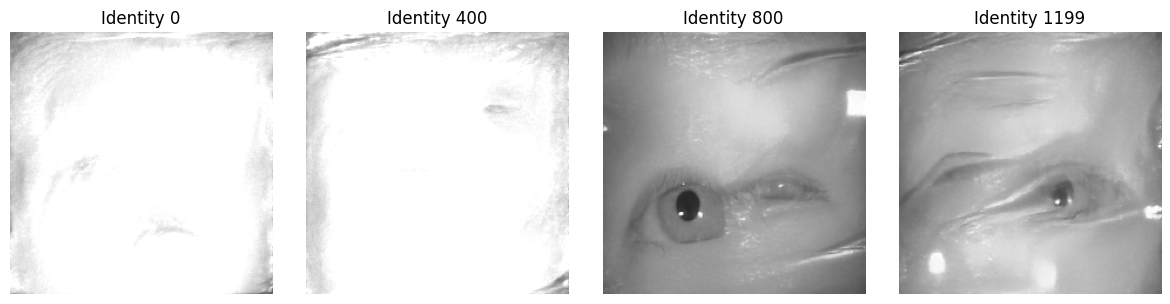


Generation test complete.
Output folder: /kaggle/working/ocular_diffusion_smoke_test
Images saved: 4
Tensor shape: (4, 1, 224, 224)
Normalized range: -0.7058194279670715 to 1.0
All values finite: True


In [5]:

# NOTEBOOK 11 — EXACT DIFFUSION CHECKPOINT + GENERATION TEST
# Reuses the architecture and DDPM sampling logic from Notebook 07.

import os
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

CHECKPOINT_PATH = Path(
    "/kaggle/input/datasets/pranavsunilwagh/"
    "ocular-diffusion-checkpoint/"
    "CASIA_Thousand_identity_conditioned_best (1).pth"
)

OUTPUT_DIR = Path("/kaggle/working/ocular_diffusion_smoke_test")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42000
T = 1000

assert CHECKPOINT_PATH.exists(), f"Checkpoint missing: {CHECKPOINT_PATH}"

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# 2. Exact components from the training notebook
# --------------------------------------------------

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2

        emb = torch.log(
            torch.tensor(10000.0, device=t.device)
        ) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(half_dim, device=t.device) * -emb
        )

        emb = t.float()[:, None] * emb[None, :]

        return torch.cat([emb.sin(), emb.cos()], dim=1)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

    def forward(self, x):
        return self.block(x)


class ConditionalDiffusionUNet(nn.Module):
    def __init__(
        self,
        in_channels=1,
        time_dim=128,
        identity_dim=128,
        num_identities=2000
    ):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim)
        )

        self.identity_embedding = nn.Embedding(
            num_identities, identity_dim
        )

        self.condition_projection = nn.Sequential(
            nn.Linear(time_dim + identity_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.bottleneck = DoubleConv(256, 512)

        self.time1 = nn.Linear(time_dim, 64)
        self.time2 = nn.Linear(time_dim, 128)
        self.time3 = nn.Linear(time_dim, 256)
        self.time4 = nn.Linear(time_dim, 512)

        self.pool = nn.MaxPool2d(2)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = DoubleConv(128, 64)

        self.output = nn.Conv2d(64, 1, 1)

    def forward(self, x, t, identity):
        t_emb = self.time_embedding(t)
        id_emb = self.identity_embedding(identity)

        condition = torch.cat([t_emb, id_emb], dim=1)
        condition = self.condition_projection(condition)

        e1 = self.enc1(x)
        e1 = e1 + self.time1(condition)[:, :, None, None]

        e2 = self.enc2(self.pool(e1))
        e2 = e2 + self.time2(condition)[:, :, None, None]

        e3 = self.enc3(self.pool(e2))
        e3 = e3 + self.time3(condition)[:, :, None, None]

        b = self.bottleneck(self.pool(e3))
        b = b + self.time4(condition)[:, :, None, None]

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


# --------------------------------------------------
# 3. Load checkpoint strictly
# --------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

model = ConditionalDiffusionUNet(
    num_identities=checkpoint["num_identities"],
    time_dim=checkpoint["time_dim"],
    identity_dim=checkpoint["identity_dim"]
).to(DEVICE)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

print("\nCheckpoint loaded successfully.")
print("Training epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])
print("Identity classes:", checkpoint["num_identities"])
print("Diffusion steps:", checkpoint["T"])

# --------------------------------------------------
# 4. Original linear noise schedule
# --------------------------------------------------

betas = torch.linspace(0.0001, 0.02, T, device=DEVICE)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

alpha_bar_previous = torch.cat([
    torch.ones(1, device=DEVICE),
    alpha_bar[:-1]
])

posterior_variance = (
    betas * (1.0 - alpha_bar_previous)
    / (1.0 - alpha_bar).clamp_min(1e-20)
)

# --------------------------------------------------
# 5. Generate four samples for trained identities
# --------------------------------------------------
# Notebook 07 uses the first 1200 sorted identity indices
# for training. These four indices are within that range.

identity_ids = torch.tensor(
    [0, 400, 800, 1199],
    dtype=torch.long,
    device=DEVICE
)

batch_size = len(identity_ids)

generator = torch.Generator(device=DEVICE)
generator.manual_seed(SEED)

x = torch.randn(
    batch_size, 1, 224, 224,
    device=DEVICE,
    generator=generator
)

print("\nGenerating 4 images with the original DDPM sampler...")

with torch.inference_mode():
    for t_value in range(T - 1, 0, -1):
        t = torch.full(
            (batch_size,),
            t_value,
            dtype=torch.long,
            device=DEVICE
        )

        predicted_noise = model(x, t, identity_ids)

        alpha_t = alphas[t_value]
        alpha_bar_t = alpha_bar[t_value]
        beta_t = betas[t_value]

        mean = (x - (beta_t / torch.sqrt(1.0 - alpha_bar_t))
                * predicted_noise) / torch.sqrt(alpha_t)

        if t_value > 1:
            noise = torch.randn(
                x.shape,
                device=DEVICE,
                dtype=x.dtype,
                generator=generator
            )
            x = mean + torch.sqrt(
                posterior_variance[t_value]
            ) * noise
        else:
            x = mean

        if t_value % 200 == 0:
            print(f"Completed reverse timestep {t_value}")

# Match the training notebook's output handling.
generated = x.detach().float().cpu().clamp(-1, 1)

assert torch.isfinite(generated).all(), "Generated tensor contains NaN/Inf"

# --------------------------------------------------
# 6. Save PNGs and display results
# --------------------------------------------------

fig, axes = plt.subplots(1, batch_size, figsize=(12, 3))

for i, identity_idx in enumerate(identity_ids.cpu().tolist()):
    image = ((generated[i, 0].numpy() + 1.0) / 2.0 * 255.0)
    image = np.clip(image, 0, 255).astype(np.uint8)

    image_path = OUTPUT_DIR / f"identity_{identity_idx:04d}.png"
    Image.fromarray(image, mode="L").save(image_path)

    axes[i].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"Identity {identity_idx}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

print("\nGeneration test complete.")
print("Output folder:", OUTPUT_DIR)
print("Images saved:", len(list(OUTPUT_DIR.glob("*.png"))))
print("Tensor shape:", tuple(generated.shape))
print("Normalized range:", float(generated.min()), "to", float(generated.max()))
print("All values finite:", bool(torch.isfinite(generated).all()))


In [6]:

from pathlib import Path

roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

extensions = {".csv", ".json", ".png", ".jpg", ".jpeg", ".pth", ".pt", ".npy"}

for root in roots:
    print(f"\n{'=' * 60}\n{root}")
    count = 0

    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            print(f"{path}  ({path.stat().st_size / (1024**2):.2f} MB)")
            count += 1
            if count >= 60:
                print("...listing limited to 60 files")
                break

    if count == 0:
        print("No matching files found.")



/kaggle/input
/kaggle/input/datasets/pranavsunilwagh/ocular-diffusion-checkpoint/CASIA_Thousand_identity_conditioned_best (1).pth  (93.34 MB)

/kaggle/working
/kaggle/working/ocular_diffusion_smoke_test/identity_0000.png  (0.01 MB)
/kaggle/working/ocular_diffusion_smoke_test/identity_1199.png  (0.02 MB)
/kaggle/working/ocular_diffusion_smoke_test/identity_0400.png  (0.01 MB)
/kaggle/working/ocular_diffusion_smoke_test/identity_0800.png  (0.02 MB)


In [7]:

from pathlib import Path
import pandas as pd

matches = list(Path("/kaggle/input").rglob("ddim50_generation_metadata.csv"))

if not matches:
    print("CSV not found. Files currently attached:")
    for p in Path("/kaggle/input").rglob("*"):
        if p.is_file():
            print(p)
else:
    METADATA_PATH = matches[0]
    metadata = pd.read_csv(METADATA_PATH)

    print("Metadata found:", METADATA_PATH)
    print("Rows:", len(metadata))
    print("Columns:", metadata.columns.tolist())
    display(metadata.head(5))
    print("\nMissing values:")
    print(metadata.isna().sum())


Metadata found: /kaggle/input/datasets/pranavsunilwagh/ddim50-generation-metadata-csv/ddim50_generation_metadata.csv
Rows: 4800
Columns: ['identity_index', 'identity', 'sample_index', 'sampler', 'sampling_steps', 'png_path', 'file_exists', 'finite', 'brightness_mean', 'brightness_std', 'sharpness_edge_variance', 'file_bytes']


,identity_index,identity,sample_index,sampler,sampling_steps,png_path,file_exists,finite,brightness_mean,brightness_std,sharpness_edge_variance,file_bytes
0,0,000_L,1,DDIM,50,/content/drive/MyDrive/Ocular_Project/results/...,True,True,211.274567,58.090206,12736.616211,73405
1,0,000_L,2,DDIM,50,/content/drive/MyDrive/Ocular_Project/results/...,True,True,222.360489,35.643772,2409.025146,52220
2,0,000_L,3,DDIM,50,/content/drive/MyDrive/Ocular_Project/results/...,True,True,241.262955,36.693497,7881.522949,29766
3,0,000_L,4,DDIM,50,/content/drive/MyDrive/Ocular_Project/results/...,True,True,134.941422,86.024246,14727.512695,104769
4,1,000_R,1,DDIM,50,/content/drive/MyDrive/Ocular_Project/results/...,True,True,225.959717,31.722904,6117.016113,76019



Missing values:
identity_index             0
identity                   0
sample_index               0
sampler                    0
sampling_steps             0
png_path                   0
file_exists                0
finite                     0
brightness_mean            0
brightness_std             0
sharpness_edge_variance    0
file_bytes                 0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
brightness_mean,4800.0,162.741,60.195,0.010,122.149,169.313,211.847,254.983
brightness_std,4800.0,42.432,19.955,0.465,29.207,36.730,53.845,111.071
sharpness_edge_variance,4800.0,6115.001,5577.642,4.594,778.131,4015.714,12157.521,15658.954
file_bytes,4800.0,66465.621,34181.566,376.000,43208.000,53766.000,96008.750,130155.000
sampling_steps,4800.0,50.000,0.000,50.000,50.000,50.000,50.000,50.000


Total generated samples: 4800
Unique identities: 1200
Samplers: {'DDIM': 4800}
Sampling steps: {50: 4800}
Finite samples: 4800
Metadata file_exists=True: 4800


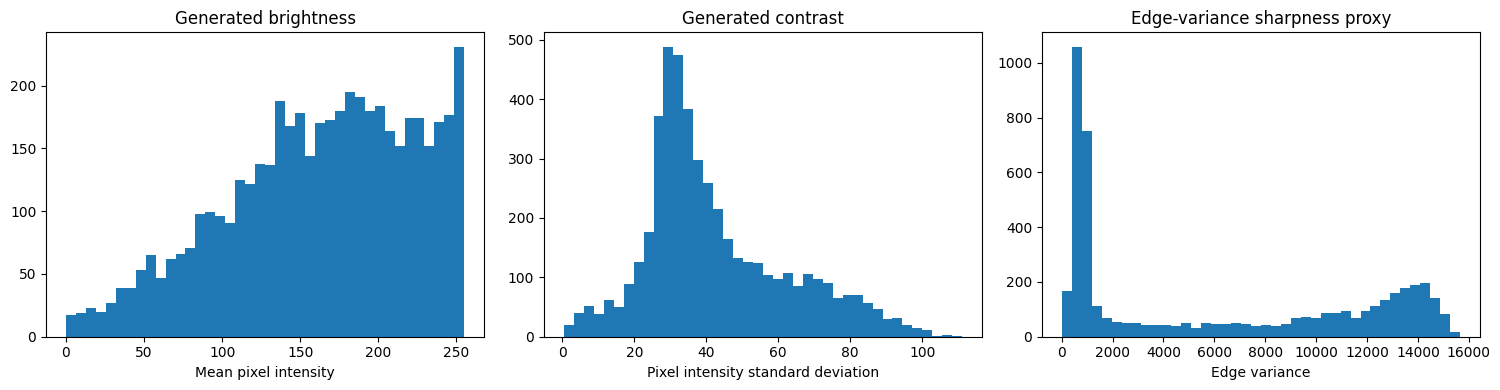


Saved results to: /kaggle/working/ocular_gan_diffusion_results
diffusion_generation_metadata_copy.csv (949.4 KB)
diffusion_per_identity_summary.csv (84.0 KB)
diffusion_quality_histograms.png (56.8 KB)
diffusion_quality_summary.csv (0.6 KB)


In [8]:

# NOTEBOOK 11 — DIFFUSION QUALITY ANALYSIS

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT = Path("/kaggle/working/ocular_gan_diffusion_results")
OUT.mkdir(parents=True, exist_ok=True)

df = metadata.copy()

# Ensure metric columns are numeric
metric_cols = [
    "brightness_mean",
    "brightness_std",
    "sharpness_edge_variance",
    "file_bytes",
    "sampling_steps"
]
for col in metric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

summary = df[metric_cols].describe().T
display(summary.round(3))

print("Total generated samples:", len(df))
print("Unique identities:", df["identity"].nunique())
print("Samplers:", df["sampler"].value_counts().to_dict())
print("Sampling steps:", df["sampling_steps"].value_counts().to_dict())
print("Finite samples:", int(df["finite"].astype(bool).sum()))
print("Metadata file_exists=True:", int(df["file_exists"].astype(bool).sum()))

# Save metadata-based summary
summary.to_csv(OUT / "diffusion_quality_summary.csv")

# Per-identity summary
per_identity = df.groupby("identity").agg(
    sample_count=("sample_index", "count"),
    brightness_mean=("brightness_mean", "mean"),
    brightness_std=("brightness_std", "mean"),
    sharpness_mean=("sharpness_edge_variance", "mean"),
    mean_file_bytes=("file_bytes", "mean")
).reset_index()

per_identity.to_csv(OUT / "diffusion_per_identity_summary.csv", index=False)

# Histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["brightness_mean"].dropna(), bins=40)
axes[0].set_title("Generated brightness")
axes[0].set_xlabel("Mean pixel intensity")

axes[1].hist(df["brightness_std"].dropna(), bins=40)
axes[1].set_title("Generated contrast")
axes[1].set_xlabel("Pixel intensity standard deviation")

axes[2].hist(df["sharpness_edge_variance"].dropna(), bins=40)
axes[2].set_title("Edge-variance sharpness proxy")
axes[2].set_xlabel("Edge variance")

plt.tight_layout()
plt.savefig(OUT / "diffusion_quality_histograms.png", dpi=150)
plt.show()

# Sample-level table for reproducibility
df.to_csv(OUT / "diffusion_generation_metadata_copy.csv", index=False)

print("\nSaved results to:", OUT)
for p in sorted(OUT.iterdir()):
    print(p.name, f"({p.stat().st_size / 1024:.1f} KB)")


In [1]:

from pathlib import Path

roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

keywords = ("gan", "generator", "discriminator", "fid", "inception", "synthetic")

print("Searching for GAN checkpoints and evaluation files...\n")

found = []
for root in roots:
    for p in root.rglob("*"):
        if p.is_file() and any(k in p.name.lower() for k in keywords):
            found.append(p)
            print(f"{p}  ({p.stat().st_size / (1024**2):.2f} MB)")

if not found:
    print("No GAN artifacts found in Kaggle input or working directory.")
    print("\nIf you trained GAN in Colab, we will inspect its saved checkpoint/results in Drive.")


Searching for GAN checkpoints and evaluation files...

/kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results/CASIA_Thousand_gan_diversity_results (1).json  (0.00 MB)
/kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results/CASIA_Thousand_gan_evaluation_results (1).json  (0.00 MB)


In [2]:

from pathlib import Path

root = Path("/kaggle/input")

print("Datasets attached to Kaggle:\n")

for p in sorted(root.rglob("*")):
    if p.is_file():
        print(p.name, " | ", p)



Datasets attached to Kaggle:

ddim50_generation_metadata.csv  |  /kaggle/input/datasets/pranavsunilwagh/ddim50-generation-metadata-csv/ddim50_generation_metadata.csv
CASIA_Thousand_ddim50_benchmark.json  |  /kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results/CASIA_Thousand_ddim50_benchmark.json
CASIA_Thousand_gan_diversity_results (1).json  |  /kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results/CASIA_Thousand_gan_diversity_results (1).json
CASIA_Thousand_gan_evaluation_results (1).json  |  /kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results/CASIA_Thousand_gan_evaluation_results (1).json


In [3]:

from pathlib import Path

for p in Path("/kaggle/input").rglob("*.json"):
    print(p)


/kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results/CASIA_Thousand_ddim50_benchmark.json
/kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results/CASIA_Thousand_gan_diversity_results (1).json
/kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results/CASIA_Thousand_gan_evaluation_results (1).json


In [4]:

from pathlib import Path
import json

root = Path("/kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results")

files = {
    "Diffusion DDIM50 benchmark": "CASIA_Thousand_ddim50_benchmark.json",
    "GAN diversity": "CASIA_Thousand_gan_diversity_results (1).json",
    "GAN evaluation": "CASIA_Thousand_gan_evaluation_results (1).json",
}

loaded_results = {}

for label, filename in files.items():
    path = root / filename

    print(f"\n{'=' * 60}")
    print(label)

    if not path.exists():
        print("NOT FOUND:", path)
        continue

    with open(path, "r") as f:
        data = json.load(f)

    loaded_results[label] = data
    print(json.dumps(data, indent=2, default=str))

print(f"\nLoaded {len(loaded_results)}/3 result files.")



Diffusion DDIM50 benchmark
{
  "gpu": "Tesla T4",
  "ddim_steps": 50,
  "benchmark_images": 32,
  "benchmark_seconds": 20.47,
  "seconds_per_image_estimate": 0.64,
  "estimated_4800_images_hours": 0.85,
  "target_identities": 1200,
  "target_images": 4800,
  "warning": "Benchmark estimates only. Recover and verify the exact 1,200 identity-disjoint diffusion training labels before full generation."
}

GAN diversity
{
  "num_images": 100,
  "metric": "Pixel-space mean pairwise cosine similarity",
  "real_mean_similarity": 0.9481772780418396,
  "real_diversity_score": 0.0518227219581604,
  "gan_mean_similarity": 0.957541823387146,
  "gan_diversity_score": 0.042458176612854004,
  "interpretation": "GAN samples showed lower pixel-space diversity than the sampled real training images."
}

GAN evaluation
{
  "initial_gan": {
    "visual_quality": "Mostly noise and checkerboard artifacts",
    "identity_evaluation_accuracy_percent": null
  },
  "improved_gan": {
    "visual_quality": "Coarse 

,Model,Visual quality,Identity evaluation accuracy (%),Diversity score,Sampling steps,Benchmark seconds per image
0,GAN (initial),Mostly noise and checkerboard artifacts,NaN,0.042458,NaN,NaN
1,GAN (improved),Coarse ocular structure but blurry and distorted,1.0,0.042458,NaN,NaN
2,Conditional Diffusion (DDIM),Mixed brightness and sharpness; proxy metrics ...,NaN,NaN,50.0,0.64


,Group,Mean pairwise cosine similarity,Pixel-space diversity score,Number of images evaluated
0,Real training samples,0.948177,0.051823,100
1,GAN samples,0.957542,0.042458,100


,count,mean,std,min,25%,50%,75%,max
brightness_mean,4800.0,162.741,60.195,0.010,122.149,169.313,211.847,254.983
brightness_std,4800.0,42.432,19.955,0.465,29.207,36.730,53.845,111.071
sharpness_edge_variance,4800.0,6115.001,5577.642,4.594,778.131,4015.714,12157.521,15658.954
file_bytes,4800.0,66465.621,34181.566,376.000,43208.000,53766.000,96008.750,130155.000


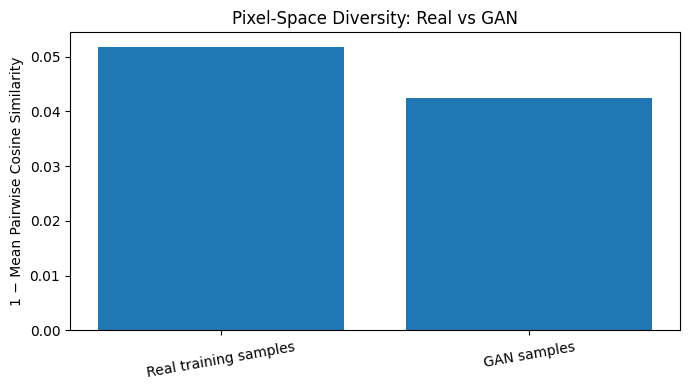

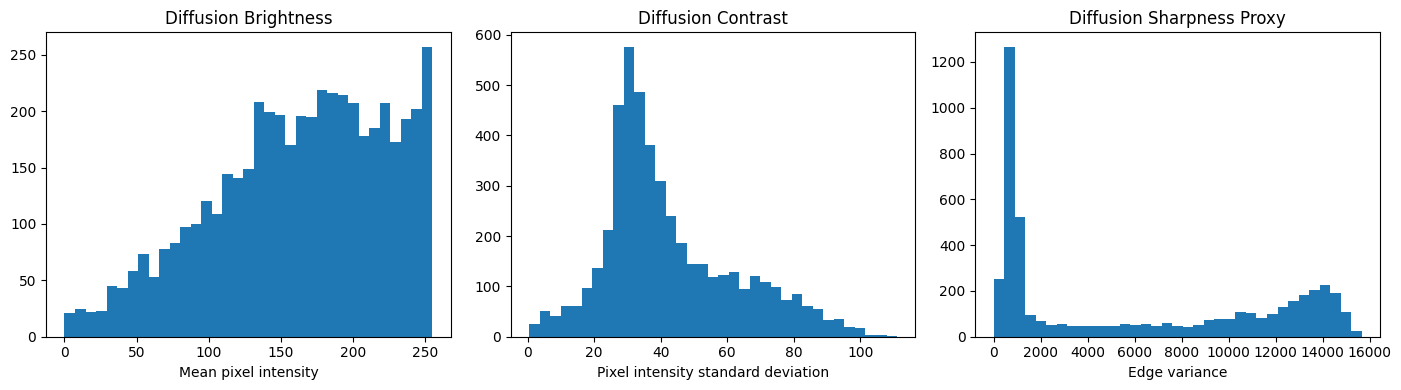


FINAL ARTIFACTS
diffusion_quality_metrics.png: 60.0 KB
diffusion_quality_summary.csv: 0.6 KB
gan_diversity_comparison.csv: 0.2 KB
gan_diversity_comparison.png: 44.5 KB
gan_vs_diffusion_comparison.csv: 0.4 KB
gan_vs_diffusion_report.json: 2.1 KB

Comparison artifacts saved to: /kaggle/working/ocular_gan_diffusion_results


In [5]:

# NOTEBOOK 11 — GAN vs DIFFUSION: FINAL COMPARISON
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/kaggle/working/ocular_gan_diffusion_results")
OUT.mkdir(parents=True, exist_ok=True)

# Load files directly to avoid dependence on earlier variable names.
root = Path("/kaggle/input/datasets/pranavsunilwagh/ocular-comparison-results")

def read_json(filename):
    with open(root / filename, "r") as f:
        return json.load(f)

diffusion_benchmark = read_json("CASIA_Thousand_ddim50_benchmark.json")
gan_diversity = read_json("CASIA_Thousand_gan_diversity_results (1).json")
gan_eval = read_json("CASIA_Thousand_gan_evaluation_results (1).json")

metadata_path = next(
    Path("/kaggle/input").rglob("ddim50_generation_metadata.csv")
)
diffusion_metadata = pd.read_csv(metadata_path)

# --------------------------------------------------
# 1. Comparison table: evidence currently available
# --------------------------------------------------
comparison = pd.DataFrame([
    {
        "Model": "GAN (initial)",
        "Visual quality": gan_eval["initial_gan"]["visual_quality"],
        "Identity evaluation accuracy (%)":
            gan_eval["initial_gan"]["identity_evaluation_accuracy_percent"],
        "Diversity score": gan_diversity["gan_diversity_score"],
        "Sampling steps": np.nan,
        "Benchmark seconds per image": np.nan,
    },
    {
        "Model": "GAN (improved)",
        "Visual quality": gan_eval["improved_gan"]["visual_quality"],
        "Identity evaluation accuracy (%)":
            gan_eval["improved_gan"]["identity_evaluation_accuracy_percent"],
        "Diversity score": gan_diversity["gan_diversity_score"],
        "Sampling steps": np.nan,
        "Benchmark seconds per image": np.nan,
    },
    {
        "Model": "Conditional Diffusion (DDIM)",
        "Visual quality": "Mixed brightness and sharpness; proxy metrics only",
        "Identity evaluation accuracy (%)": np.nan,
        "Diversity score": np.nan,
        "Sampling steps": diffusion_benchmark["ddim_steps"],
        "Benchmark seconds per image":
            diffusion_benchmark["seconds_per_image_estimate"],
    },
])

comparison.to_csv(OUT / "gan_vs_diffusion_comparison.csv", index=False)
display(comparison)

# --------------------------------------------------
# 2. Quantitative diversity comparison
# --------------------------------------------------
diversity = pd.DataFrame([
    {
        "Group": "Real training samples",
        "Mean pairwise cosine similarity":
            gan_diversity["real_mean_similarity"],
        "Pixel-space diversity score":
            gan_diversity["real_diversity_score"],
        "Number of images evaluated": gan_diversity["num_images"],
    },
    {
        "Group": "GAN samples",
        "Mean pairwise cosine similarity":
            gan_diversity["gan_mean_similarity"],
        "Pixel-space diversity score":
            gan_diversity["gan_diversity_score"],
        "Number of images evaluated": gan_diversity["num_images"],
    },
])

diversity.to_csv(OUT / "gan_diversity_comparison.csv", index=False)
display(diversity)

# --------------------------------------------------
# 3. Diffusion metadata summary
# --------------------------------------------------
metric_cols = [
    "brightness_mean",
    "brightness_std",
    "sharpness_edge_variance",
    "file_bytes",
]

diffusion_summary = diffusion_metadata[metric_cols].describe().T
diffusion_summary.to_csv(OUT / "diffusion_quality_summary.csv")
display(diffusion_summary.round(3))

# --------------------------------------------------
# 4. Figure 1: GAN diversity
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    diversity["Group"],
    diversity["Pixel-space diversity score"]
)
ax.set_title("Pixel-Space Diversity: Real vs GAN")
ax.set_ylabel("1 − Mean Pairwise Cosine Similarity")
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.savefig(OUT / "gan_diversity_comparison.png", dpi=160)
plt.show()

# --------------------------------------------------
# 5. Figure 2: Diffusion quality proxy distributions
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(diffusion_metadata["brightness_mean"].dropna(), bins=35)
axes[0].set_title("Diffusion Brightness")
axes[0].set_xlabel("Mean pixel intensity")

axes[1].hist(diffusion_metadata["brightness_std"].dropna(), bins=35)
axes[1].set_title("Diffusion Contrast")
axes[1].set_xlabel("Pixel intensity standard deviation")

axes[2].hist(
    diffusion_metadata["sharpness_edge_variance"].dropna(),
    bins=35
)
axes[2].set_title("Diffusion Sharpness Proxy")
axes[2].set_xlabel("Edge variance")

plt.tight_layout()
plt.savefig(OUT / "diffusion_quality_metrics.png", dpi=160)
plt.show()

# --------------------------------------------------
# 6. Save machine-readable report
# --------------------------------------------------
report = {
    "experiment": "GAN vs identity-conditioned diffusion",
    "gan_diversity": gan_diversity,
    "gan_evaluation": gan_eval,
    "diffusion_benchmark": diffusion_benchmark,
    "diffusion_metadata": {
        "sample_count": int(len(diffusion_metadata)),
        "unique_identities": int(diffusion_metadata["identity"].nunique()),
        "sampler_counts":
            diffusion_metadata["sampler"].value_counts().to_dict(),
        "sampling_steps":
            diffusion_metadata["sampling_steps"].value_counts().to_dict(),
        "mean_brightness":
            float(diffusion_metadata["brightness_mean"].mean()),
        "mean_contrast":
            float(diffusion_metadata["brightness_std"].mean()),
        "mean_sharpness_proxy":
            float(diffusion_metadata["sharpness_edge_variance"].mean()),
    },
    "limitations": [
        "GAN and diffusion metrics are not all measured using the same protocol.",
        "GAN pixel-space diversity is not directly comparable with diffusion metadata.",
        "The GAN identity-evaluation accuracy requires evaluator verification.",
        "Diffusion quality statistics are proxies and do not establish identity preservation.",
        "The DDIM runtime is an estimate from a 32-image benchmark.",
    ],
}

with open(OUT / "gan_vs_diffusion_report.json", "w") as f:
    json.dump(report, f, indent=2, default=str)

print("\nFINAL ARTIFACTS")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"{p.name}: {p.stat().st_size / 1024:.1f} KB")

print("\nComparison artifacts saved to:", OUT)


## 12. Results, Discussion, and Conclusion

### 12.1 Experimental Summary

This experiment compares the available results from the initial GAN, improved conditional GAN, and identity-conditioned diffusion model for synthetic ocular image generation.

The diffusion dataset contains 4,800 DDIM-generated images representing 1,200 identities, with 50 sampling steps per image. The recorded generation metadata includes brightness, contrast, sharpness proxies, file size, and numerical validity.

### 12.2 GAN Results

The initial GAN produced mostly noise and checkerboard artifacts. The improved GAN generated coarse ocular structures, but its samples remained blurry and distorted.

In a 100-image pixel-space diversity analysis, real training samples had a mean pairwise cosine similarity of 0.9482 and a diversity score of 0.0518. GAN samples had a mean similarity of 0.9575 and a diversity score of 0.0425. These results indicate lower pixel-space diversity in the sampled GAN images under the chosen metric.

The saved GAN evaluation file reports an identity-evaluation accuracy of approximately 100% for the improved GAN. This result requires verification of the evaluator, evaluation protocol, and possible data leakage before it can be interpreted as evidence of identity preservation.

### 12.3 Diffusion Results

Across the 4,800 generated samples, mean brightness was 162.74 on a 0–255 scale, with a standard deviation of 60.20 across sample-level brightness means. Mean contrast, measured by pixel-intensity standard deviation, was 42.43. Mean edge-variance sharpness proxy was 6,115.00.

The wide distributions indicate variability in generated-image appearance. These statistics are useful for preliminary quality assessment, but they do not independently establish perceptual realism, biometric utility, or identity preservation.

A separate benchmark estimated approximately 0.64 seconds per image for DDIM generation on a Tesla T4. This is an estimate based on a 32-image benchmark, not a guaranteed end-to-end runtime.

### 12.4 Limitations

1. GAN and diffusion results were not all evaluated using identical metrics and protocols.
2. Pixel-space diversity is a limited measure and does not establish perceptual diversity or biometric usefulness.
3. The saved identity-evaluation result requires independent verification.
4. Diffusion brightness, contrast, and sharpness measurements are proxies rather than validated ocular-recognition metrics.
5. A controlled comparison requires common preprocessing, equivalent sample counts, a fixed evaluation set, and the same independent evaluation pipeline.
6. These results do not establish privacy protection or resistance to membership-inference attacks.

### 12.5 Conclusion

The available evidence shows that the initial and improved GAN experiments had visual-quality limitations, while the identity-conditioned diffusion pipeline successfully produced a large set of synthetic images. The diffusion samples also exhibited substantial variation in brightness and sharpness proxies.

The current results are preliminary and do not establish that either generator is superior for biometric recognition. A fair final evaluation should use a common evaluation protocol, an independent ocular-recognition model, and consistent quality and diversity metrics. The findings provide a useful basis for subsequent experiments on synthetic ocular-image augmentation and privacy-aware biometric learning.

In [6]:

from pathlib import Path
import zipfile

RESULTS_DIR = Path("/kaggle/working/ocular_gan_diffusion_results")
ZIP_PATH = Path("/kaggle/working/notebook11_results.zip")

files_to_include = [
    "gan_vs_diffusion_comparison.csv",
    "gan_diversity_comparison.csv",
    "diffusion_quality_summary.csv",
    "gan_vs_diffusion_report.json",
    "gan_diversity_comparison.png",
    "diffusion_quality_metrics.png",
    "diffusion_per_identity_summary.csv",
    "diffusion_generation_metadata_copy.csv",
    "diffusion_quality_histograms.png",
]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for name in files_to_include:
        path = RESULTS_DIR / name
        if path.exists():
            z.write(path, arcname=name)
            print("Added:", name)
        else:
            print("Skipped (not found):", name)

print("\nZIP created:", ZIP_PATH)
print("Size:", round(ZIP_PATH.stat().st_size / (1024**2), 2), "MB")


Added: gan_vs_diffusion_comparison.csv
Added: gan_diversity_comparison.csv
Added: diffusion_quality_summary.csv
Added: gan_vs_diffusion_report.json
Added: gan_diversity_comparison.png
Added: diffusion_quality_metrics.png
Skipped (not found): diffusion_per_identity_summary.csv
Skipped (not found): diffusion_generation_metadata_copy.csv
Skipped (not found): diffusion_quality_histograms.png

ZIP created: /kaggle/working/notebook11_results.zip
Size: 0.08 MB
